<a href="https://colab.research.google.com/github/Stepanodityas/KKA3/blob/main/Tugas_KKA3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- INFO DATA ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   order_id           220 non-null    int64 
 1   tanggal            220 non-null    object
 2   kategori_produk    220 non-null    object
 3   nama_produk        220 non-null    object
 4   wilayah            220 non-null    object
 5   jumlah             220 non-null    int64 
 6   harga_satuan       220 non-null    int64 
 7   total              220 non-null    int64 
 8   metode_pembayaran  220 non-null    object
 9   rating_pelanggan   220 non-null    int64 
dtypes: int64(5), object(5)
memory usage: 17.3+ KB
None

--- STATISTIK TOTAL & KATEGORI ---
Mean Total  : Rp 238,486
Median Total: Rp 125,000

Rata-Rata per Kategori:
 kategori_produk
Elektronik           363541.666667
Fashion              353900.000000
Olahraga             209071.428571
Kesehatan            148

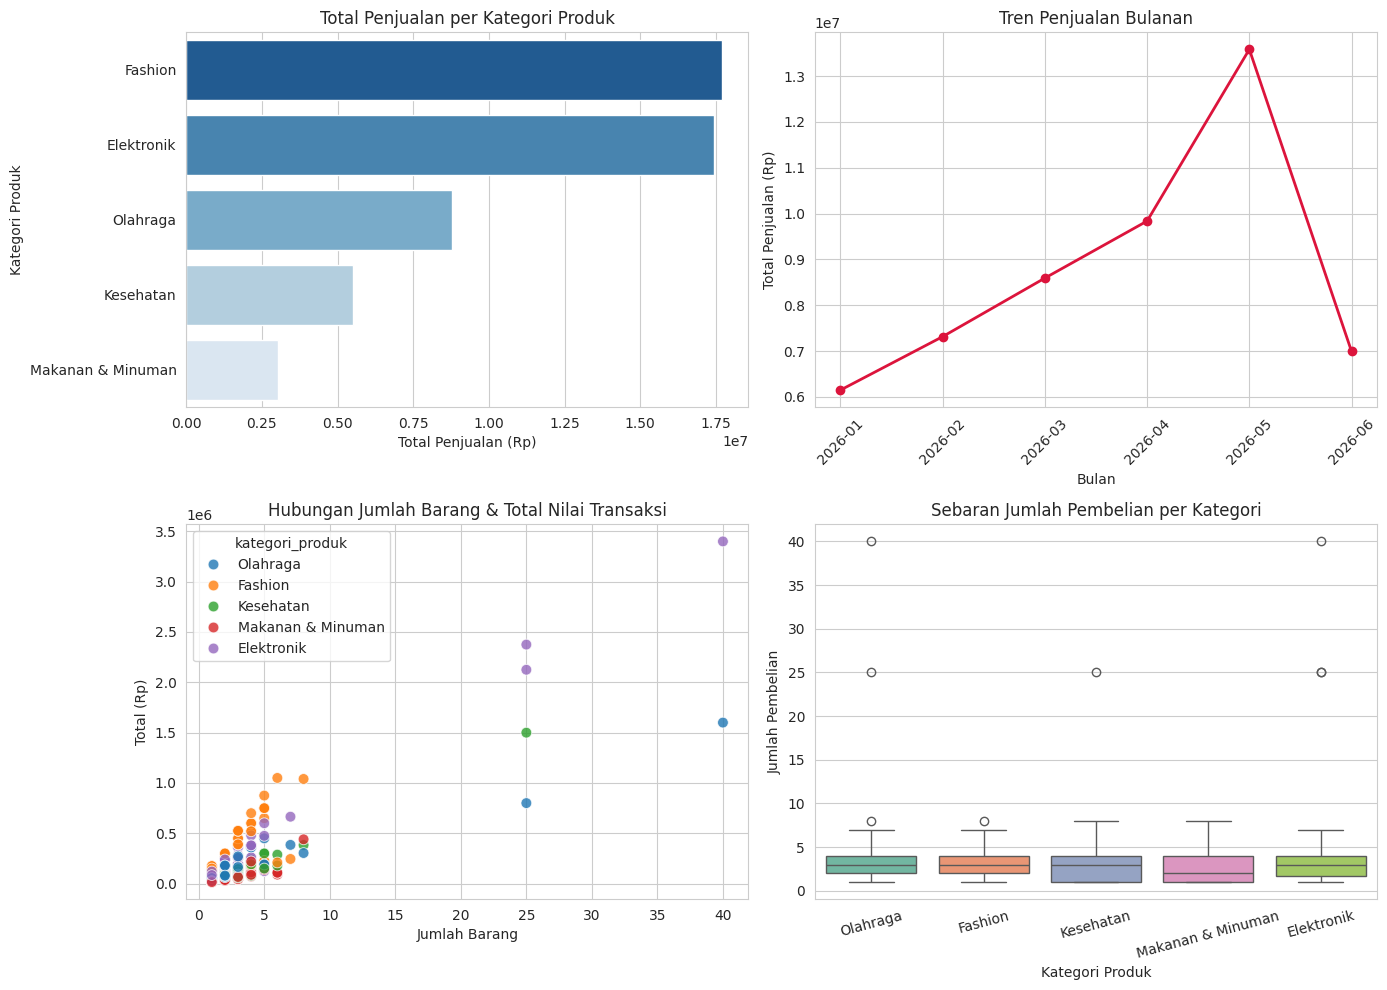

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Atur gaya visual default
sns.set_style('whitegrid')

# 1. Eksplorasi Data & Statistika
df = pd.read_csv('penjualan_nusantaramart.csv')
print("--- INFO DATA ---")
print(df.info())

print("\n--- STATISTIK TOTAL & KATEGORI ---")
print(f"Mean Total  : Rp {df['total'].mean():,.0f}")
print(f"Median Total: Rp {df['total'].median():,.0f}")

rata_kategori = df.groupby('kategori_produk')['total'].mean()
print("\nRata-Rata per Kategori:\n", rata_kategori.sort_values(ascending=False))

total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)
print("\nTotal Penjualan per Kategori:\n", total_kategori)

# 2. Persiapan Data Waktu untuk Tren Bulanan
df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')
tren_bulanan = df.groupby('bulan')['total'].sum()

print("\nTren Penjualan Bulanan:\n", tren_bulanan)

# 3. MENGGAMBAR DASHBOARD GABUNGAN (Merangkum Latihan 2 - 6)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# [Kiri Atas] Bar Chart - Latihan 2
sns.barplot(x=total_kategori.values, y=total_kategori.index, ax=axes[0, 0], palette='Blues_r', hue=total_kategori.index, legend=False)
axes[0, 0].set_title('Total Penjualan per Kategori Produk')
axes[0, 0].set_xlabel('Total Penjualan (Rp)')
axes[0, 0].set_ylabel('Kategori Produk')

# [Kanan Atas] Line Chart - Latihan 3
axes[0, 1].plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o', color='crimson', linewidth=2)
axes[0, 1].set_title('Tren Penjualan Bulanan')
axes[0, 1].set_xlabel('Bulan')
axes[0, 1].set_ylabel('Total Penjualan (Rp)')
axes[0, 1].tick_params(axis='x', rotation=45)

# [Kiri Bawah] Scatter Plot - Latihan 4 (Menggantikan Histogram untuk keberagaman)
sns.scatterplot(data=df, x='jumlah', y='total', hue='kategori_produk', ax=axes[1, 0], s=60, alpha=0.8)
axes[1, 0].set_title('Hubungan Jumlah Barang & Total Nilai Transaksi')
axes[1, 0].set_xlabel('Jumlah Barang')
axes[1, 0].set_ylabel('Total (Rp)')

# [Kanan Bawah] Boxplot Outlier - Latihan 5
sns.boxplot(data=df, x='kategori_produk', y='jumlah', ax=axes[1, 1], palette='Set2', hue='kategori_produk', legend=False)
axes[1, 1].set_title('Sebaran Jumlah Pembelian per Kategori')
axes[1, 1].set_xlabel('Kategori Produk')
axes[1, 1].set_ylabel('Jumlah Pembelian')
axes[1, 1].tick_params(axis='x', rotation=15)

# Penyesuaian layout agar grafik tidak menumpuk
plt.tight_layout()
plt.show()

/tmp/ipykernel_1209/3262644798.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=worth_it_players, y='Name', x='Value_Num', ax=ax1, palette='mako')
/tmp/ipykernel_1209/3262644798.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Kategori', y='Value_Num', palette='Set2', ax=ax4)
/tmp/ipykernel_1209/3262644798.py:75: UserWarning: tight_layout not applied: number of columns in subplot specifications must be multiples of one another.
  plt.tight_layout()


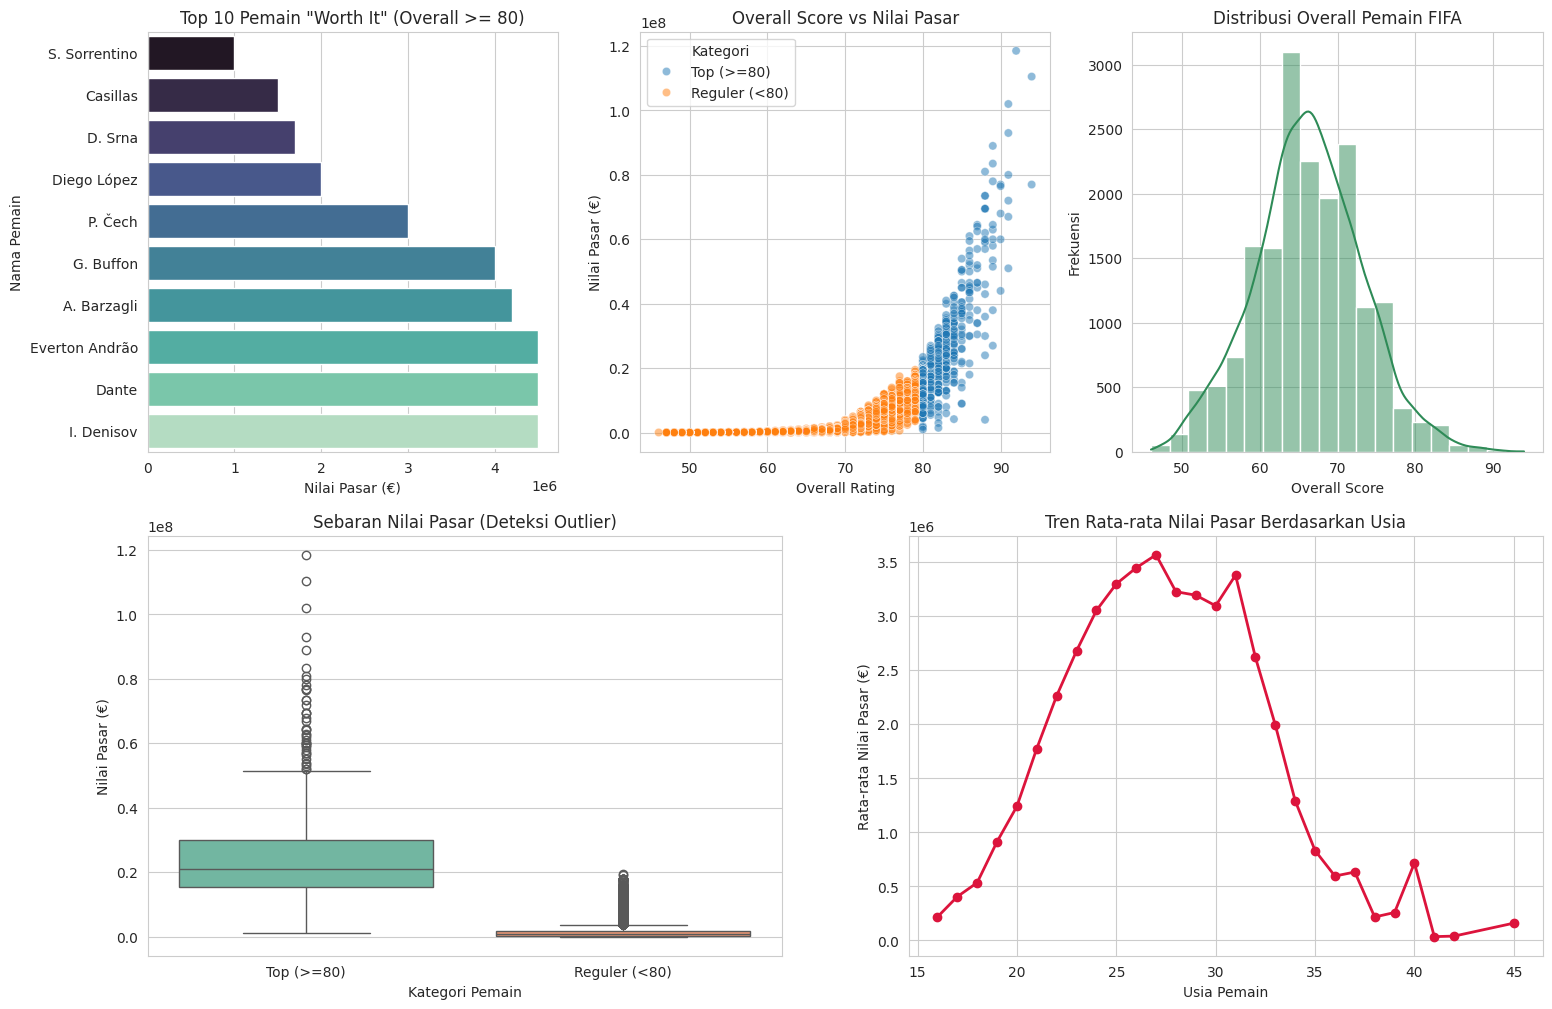

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Memuat dan membersihkan data
# Menggunakan compression='zip' karena fifa_eda_stats.csv dalam bentuk arsip
df = pd.read_csv('fifa_eda_stats.csv', compression='zip')

# Fungsi konversi string mata uang ke numerik (Euro)
def clean_currency(x):
    if isinstance(x, str):
        x = x.replace('€', '')
        if 'M' in x:
            return float(x.replace('M', '')) * 1000000
        elif 'K' in x:
            return float(x.replace('K', '')) * 1000
    return float(x)

df['Value_Num'] = df['Value'].apply(clean_currency)
df['Wage_Num'] = df['Wage'].apply(clean_currency)
df = df[df['Value_Num'] > 0] # Filter pemain yang memiliki nilai pasar

# 2. Menentukan metrik 'Worth It'
# Fokus pada Top Players (Overall >= 80). Rasio Value/Overall terendah = Paling Worth It
top_players = df[df['Overall'] >= 80].copy()
top_players['Value_per_Overall'] = top_players['Value_Num'] / top_players['Overall']
worth_it_players = top_players.sort_values('Value_per_Overall', ascending=True).head(10)

# Kategori Status Pemain
df['Kategori'] = np.where(df['Overall'] >= 80, 'Top (>=80)', 'Reguler (<80)')
tren_umur = df.groupby('Age')['Value_Num'].mean()

# 3. Membuat Dashboard 5 Grafik dalam 1 Figure (Subplots)
sns.set_style('whitegrid')
fig = plt.figure(figsize=(18, 12))

# Layout Grid Khusus
ax1 = plt.subplot(2, 3, 1) # Bar Chart
ax2 = plt.subplot(2, 3, 2) # Scatter Plot
ax3 = plt.subplot(2, 3, 3) # Histogram
ax4 = plt.subplot(2, 2, 3) # Boxplot
ax5 = plt.subplot(2, 2, 4) # Line Chart

# [1] Bar Chart: 10 Pemain Paling Worth It
sns.barplot(data=worth_it_players, y='Name', x='Value_Num', ax=ax1, palette='mako')
ax1.set_title('Top 10 Pemain "Worth It" (Overall >= 80)')
ax1.set_xlabel('Nilai Pasar (€)')
ax1.set_ylabel('Nama Pemain')

# [2] Scatter Plot: Hubungan Overall dan Value
sns.scatterplot(data=df, x='Overall', y='Value_Num', hue='Kategori', alpha=0.5, ax=ax2)
ax2.set_title('Overall Score vs Nilai Pasar')
ax2.set_xlabel('Overall Rating')
ax2.set_ylabel('Nilai Pasar (€)')

# [3] Histogram: Distribusi Overall Score
sns.histplot(df['Overall'], bins=20, color='seagreen', kde=True, ax=ax3)
ax3.set_title('Distribusi Overall Pemain FIFA')
ax3.set_xlabel('Overall Score')
ax3.set_ylabel('Frekuensi')

# [4] Boxplot: Sebaran Harga (Deteksi Outlier)
sns.boxplot(data=df, x='Kategori', y='Value_Num', palette='Set2', ax=ax4)
ax4.set_title('Sebaran Nilai Pasar (Deteksi Outlier)')
ax4.set_ylabel('Nilai Pasar (€)')
ax4.set_xlabel('Kategori Pemain')

# [5] Line Chart: Rata-rata Harga Berdasarkan Usia
ax5.plot(tren_umur.index, tren_umur.values, marker='o', color='crimson', linewidth=2)
ax5.set_title('Tren Rata-rata Nilai Pasar Berdasarkan Usia')
ax5.set_xlabel('Usia Pemain')
ax5.set_ylabel('Rata-rata Nilai Pasar (€)')

plt.tight_layout()
plt.show()